Veri seti zaten mevcut.
100: 834 beat
101: 805 beat
102: 903 beat
103: 802 beat
104: 965 beat
105: 846 beat
106: 1320 beat
107: 859 beat
108: 823 beat
109: 840 beat
111: 801 beat
112: 802 beat
113: 806 beat
114: 859 beat
115: 800 beat
116: 910 beat
117: 801 beat
118: 912 beat
119: 1244 beat
121: 802 beat
122: 800 beat
123: 803 beat
124: 883 beat
200: 1632 beat
201: 1128 beat
202: 875 beat
203: 1251 beat
205: 885 beat
207: 1117 beat
208: 1976 beat
209: 1184 beat
210: 1027 beat
212: 800 beat
213: 1410 beat
214: 1059 beat
215: 968 beat
217 okunamadı: [Errno 2] No such file or directory: '/content/mitdb/217.hea'
219 okunamadı: [Errno 2] No such file or directory: '/content/mitdb/219.hea'
220 okunamadı: [Errno 2] No such file or directory: '/content/mitdb/220.hea'
221 okunamadı: [Errno 2] No such file or directory: '/content/mitdb/221.hea'
222 okunamadı: [Errno 2] No such file or directory: '/content/mitdb/222.hea'
223 okunamadı: [Errno 2] No such file or directory: '/content/mitdb/223.hea'

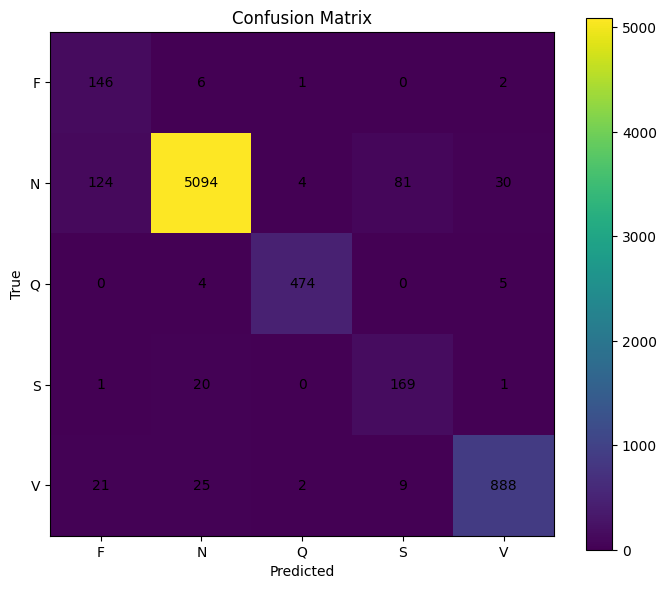

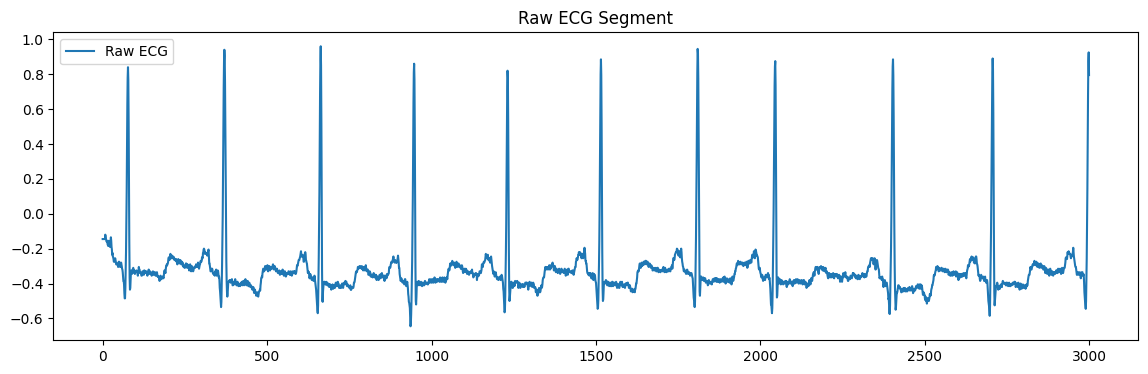

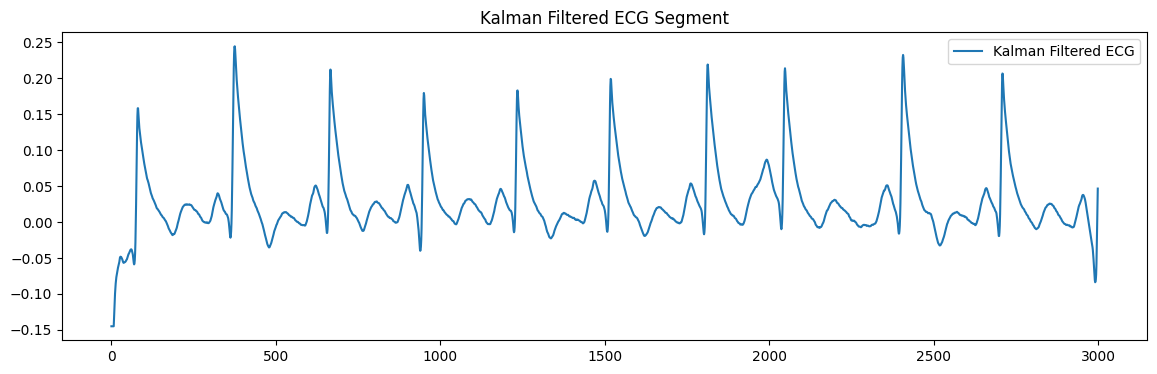


İlk 5 test örneği için fuzzy membership değerleri:
Sample 0: true=N, pred=N, memberships=[0.2382 0.0423 0.2365 0.2377 0.2453]
Sample 1: true=N, pred=N, memberships=[0.2418 0.1124 0.2427 0.242  0.1611]
Sample 2: true=N, pred=N, memberships=[0.1933 0.041  0.1942 0.1935 0.378 ]
Sample 3: true=N, pred=N, memberships=[0.1739 0.0432 0.1746 0.174  0.4344]
Sample 4: true=F, pred=F, memberships=[0.2553 0.0318 0.2543 0.255  0.2036]

LIME explanation for test sample 0
True class: N
Predicted class: N


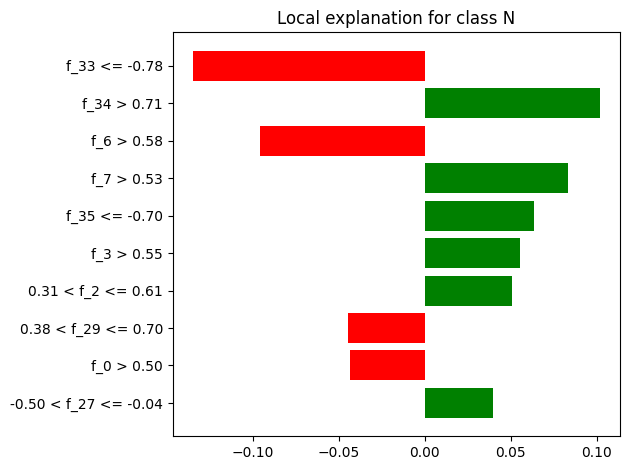

LIME explanation kaydedildi: /content/lime_explanation.html

Offline model artifacts saved.

Offline tahmin örneği:
{'predicted_class': np.str_('V'), 'probabilities': {np.str_('F'): 9.78352896313211e-06, np.str_('N'): 0.0008869343654829247, np.str_('Q'): 3.1955659047515124e-05, np.str_('S'): 0.00018153728341471664, np.str_('V'): 0.9988897891630915}}


In [ ]:
# ============================================================
# ECG + Kalman + Fuzzy +SVM+LIME + Offline AI
# Dataset: MIT-BIH Arrhythmia Database (automatic download)
# Google Colab compatible
# ============================================================

# -----------------------------
# 1) INSTALL LIBRARIES
# -----------------------------
!pip -q install wfdb pywavelets lime scikit-fuzzy

# -----------------------------
# 2) IMPORTS
# -----------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import pywt
import random
import warnings
warnings.filterwarnings("ignore")

from scipy.signal import medfilt, find_peaks
from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.decomposition import PCA
from lime.lime_tabular import LimeTabularExplainer

import skfuzzy as fuzz

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# -----------------------------
# 3) DOWNLOAD DATASET AUTOMATICALLY
# -----------------------------
# Official PhysioNet MIT-BIH DB short name = "mitdb"
# This downloads the full database locally into /content/mitdb
db_dir = "/content/mitdb"

if not os.path.exists(db_dir):
    print("MIT-BIH veri seti indiriliyor...")
    wfdb.dl_database("mitdb", dl_dir=db_dir)
    print("İndirme tamamlandı.")
else:
    print("Veri seti zaten mevcut.")

# Record list
record_names = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]

# -----------------------------
# 4) BASIC SETTINGS
# -----------------------------
# Use AAMI-like simplified grouping
# N: Normal and bundle branch / escape normal-like beats
# S: Supraventricular ectopic beats
# V: Ventricular ectopic beats
# F: Fusion beats
# Q: Unknown / paced / unclassifiable
AAMI_MAP = {
    'N':'N', 'L':'N', 'R':'N', 'e':'N', 'j':'N',
    'A':'S', 'a':'S', 'J':'S', 'S':'S',
    'V':'V', 'E':'V',
    'F':'F',
    '/':'Q', 'f':'Q', 'Q':'Q'
}

VALID_SYMBOLS = set(AAMI_MAP.keys())

# -----------------------------
# 5) SIMPLE 1D KALMAN FILTER
# -----------------------------
def kalman_filter_1d(signal, process_variance=1e-5, measurement_variance=1e-2):
    """
    Simple scalar Kalman filter for 1D ECG signal denoising.
    """
    n = len(signal)
    xhat = np.zeros(n)      # estimated signal
    P = np.zeros(n)         # estimated error covariance
    xhatminus = np.zeros(n)
    Pminus = np.zeros(n)
    K = np.zeros(n)         # kalman gain

    xhat[0] = signal[0]
    P[0] = 1.0

    for k in range(1, n):
        # Prediction
        xhatminus[k] = xhat[k-1]
        Pminus[k] = P[k-1] + process_variance

        # Update
        K[k] = Pminus[k] / (Pminus[k] + measurement_variance)
        xhat[k] = xhatminus[k] + K[k] * (signal[k] - xhatminus[k])
        P[k] = (1 - K[k]) * Pminus[k]

    return xhat

# -----------------------------
# 6) ECG PREPROCESSING
# -----------------------------
def preprocess_ecg(sig):
    """
    Baseline removal + Kalman smoothing + normalization
    """
    sig = np.asarray(sig).astype(np.float32)

    # baseline wander reduction
    baseline = medfilt(sig, kernel_size=201)
    sig = sig - baseline

    # Kalman denoising
    sig_k = kalman_filter_1d(sig, process_variance=1e-5, measurement_variance=1e-2)

    # z-normalization
    std = np.std(sig_k)
    if std < 1e-8:
        std = 1e-8
    sig_k = (sig_k - np.mean(sig_k)) / std

    return sig_k

# -----------------------------
# 7) BEAT SEGMENT EXTRACTION
# -----------------------------
def extract_beats_from_record(record_name, data_dir, window_left=90, window_right=110, max_beats_per_class=1200):
    """
    Read a record + annotation, segment beats around R-peaks.
    Returns beats and labels.
    """
    record_path = os.path.join(data_dir, record_name)

    record = wfdb.rdrecord(record_path)
    ann = wfdb.rdann(record_path, 'atr')

    # Use channel 0
    sig = record.p_signal[:, 0]
    sig = preprocess_ecg(sig)

    samples = ann.sample
    symbols = ann.symbol

    beats = []
    labels = []

    class_counter = {'N':0, 'S':0, 'V':0, 'F':0, 'Q':0}

    for s, sym in zip(samples, symbols):
        if sym not in VALID_SYMBOLS:
            continue

        label = AAMI_MAP[sym]

        if class_counter[label] >= max_beats_per_class:
            continue

        start = s - window_left
        end = s + window_right

        if start < 0 or end >= len(sig):
            continue

        beat = sig[start:end]

        if len(beat) == (window_left + window_right):
            beats.append(beat)
            labels.append(label)
            class_counter[label] += 1

    return np.array(beats), np.array(labels)

# -----------------------------
# 8) FEATURE EXTRACTION
# -----------------------------
def wavelet_features(x, wavelet='db4', level=3):
    coeffs = pywt.wavedec(x, wavelet, level=level)
    feats = []
    for c in coeffs:
        feats.extend([
            np.mean(c),
            np.std(c),
            np.min(c),
            np.max(c),
            np.sum(np.square(c))
        ])
    return feats

def time_domain_features(x):
    feats = [
        np.mean(x),
        np.std(x),
        np.min(x),
        np.max(x),
        np.ptp(x),
        np.median(x),
        np.percentile(x, 25),
        np.percentile(x, 75),
        skew(x),
        kurtosis(x),
        np.sum(np.square(x)),
        np.mean(np.abs(np.diff(x))),
        np.max(np.abs(np.diff(x)))
    ]
    return feats

def peak_features(x):
    peaks, _ = find_peaks(x, distance=20)
    if len(peaks) == 0:
        return [0, 0, 0, 0]
    peak_vals = x[peaks]
    return [
        len(peaks),
        np.mean(peak_vals),
        np.max(peak_vals),
        np.std(peak_vals) if len(peak_vals) > 1 else 0
    ]

def extract_features(beat):
    return np.array(
        time_domain_features(beat) +
        peak_features(beat) +
        wavelet_features(beat)
    )

# -----------------------------
# 9) LOAD ALL RECORDS
# -----------------------------
all_beats = []
all_labels = []

for rec in record_names:
    try:
        beats, labels = extract_beats_from_record(rec, db_dir, max_beats_per_class=800)
        if len(beats) > 0:
            all_beats.append(beats)
            all_labels.append(labels)
        print(f"{rec}: {len(labels)} beat")
    except Exception as e:
        print(f"{rec} okunamadı: {e}")

X_beats = np.vstack(all_beats)
y_labels = np.concatenate(all_labels)

print("Toplam beat sayısı:", X_beats.shape[0])
print("Beat boyutu:", X_beats.shape[1])

# Optional class balancing by capping per class
df_temp = pd.DataFrame({"label": y_labels})
print("\nSınıf dağılımı:")
print(df_temp["label"].value_counts())

# -----------------------------
# 10) FEATURE MATRIX
# -----------------------------
X_features = np.array([extract_features(b) for b in X_beats])
print("Feature matrix shape:", X_features.shape)

# -----------------------------
# 11) ENCODE LABELS
# -----------------------------
le = LabelEncoder()
y = le.fit_transform(y_labels)
class_names = list(le.classes_)
print("Classes:", class_names)

# -----------------------------
# 12) TRAIN / TEST SPLIT
# -----------------------------
X_train, X_test, y_train, y_test, beats_train, beats_test = train_test_split(
    X_features, y, X_beats,
    test_size=0.2,
    stratify=y,
    random_state=SEED
)

# -----------------------------
# 13) STANDARDIZATION
# -----------------------------
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# -----------------------------
# 14) FUZZY MEMBERSHIP REPRESENTATION
# -----------------------------
# We create fuzzy membership features from PCA-reduced data using FCM
pca = PCA(n_components=min(10, X_train_sc.shape[1]))
X_train_pca = pca.fit_transform(X_train_sc)
X_test_pca = pca.transform(X_test_sc)

n_clusters = len(class_names)

# skfuzzy expects shape = (features, samples)
cntr, u_train, _, _, _, _, _ = fuzz.cluster.cmeans(
    X_train_pca.T,
    c=n_clusters,
    m=2.0,
    error=0.005,
    maxiter=1000,
    seed=SEED
)

# Memberships for test
u_test, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
    X_test_pca.T,
    cntr,
    m=2.0,
    error=0.005,
    maxiter=1000
)

# Combine original scaled features + membership features
X_train_final = np.hstack([X_train_sc, u_train.T])
X_test_final = np.hstack([X_test_sc, u_test.T])

print("Final train shape:", X_train_final.shape)
print("Final test shape:", X_test_final.shape)

# -----------------------------
# 15) LIGHTWEIGHT CLASSIFIER (SVM)
# -----------------------------
clf = SVC(
    kernel='rbf',
    C=5,
    gamma='scale',
    probability=True,
    class_weight='balanced',
    random_state=SEED
)
clf.fit(X_train_final, y_train)

# -----------------------------
# 16) EVALUATION
# -----------------------------
y_pred = clf.predict(X_test_final)
y_prob = clf.predict_proba(X_test_final)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("\nAccuracy:", acc)
print("Macro F1:", f1)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,6))
plt.imshow(cm, interpolation='nearest')
plt.title("Confusion Matrix")
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

# -----------------------------
# 17) SHOW RAW vs KALMAN FILTERED ECG EXAMPLE
# -----------------------------
example_record = '100'
record_path = os.path.join(db_dir, example_record)
record = wfdb.rdrecord(record_path)
raw_sig = record.p_signal[:3000, 0]

baseline = medfilt(raw_sig, kernel_size=201)
pre_sig = raw_sig - baseline
kalman_sig = kalman_filter_1d(pre_sig, process_variance=1e-5, measurement_variance=1e-2)

plt.figure(figsize=(14,4))
plt.plot(raw_sig, label="Raw ECG")
plt.title("Raw ECG Segment")
plt.legend()
plt.show()

plt.figure(figsize=(14,4))
plt.plot(kalman_sig, label="Kalman Filtered ECG")
plt.title("Kalman Filtered ECG Segment")
plt.legend()
plt.show()

# -----------------------------
# 18) SHOW FUZZY MEMBERSHIP OF FEW SAMPLES
# -----------------------------
print("\nİlk 5 test örneği için fuzzy membership değerleri:")
for i in range(5):
    print(f"Sample {i}: true={class_names[y_test[i]]}, pred={class_names[y_pred[i]]}, memberships={np.round(u_test[:, i], 4)}")

# -----------------------------
# 19) LIME EXPLANATION
# -----------------------------
feature_names = [f"f_{i}" for i in range(X_train_sc.shape[1])] + [f"membership_{i}" for i in range(n_clusters)]

explainer = LimeTabularExplainer(
    training_data=X_train_final,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification'
)

idx = 0
exp = explainer.explain_instance(
    X_test_final[idx],
    clf.predict_proba,
    num_features=10
)

print(f"\nLIME explanation for test sample {idx}")
print(f"True class: {class_names[y_test[idx]]}")
print(f"Predicted class: {class_names[y_pred[idx]]}")

fig = exp.as_pyplot_figure()
plt.tight_layout()
plt.show()

# Save HTML explanation
exp.save_to_file("/content/lime_explanation.html")
print("LIME explanation kaydedildi: /content/lime_explanation.html")

# -----------------------------
# 20) OFFLINE AI INFERENCE FUNCTION
# -----------------------------
# This function can be used later without internet, once model + scaler + pca + centers are stored.
import joblib

joblib.dump(clf, "/content/offline_svm_model.pkl")
joblib.dump(scaler, "/content/offline_scaler.pkl")
joblib.dump(pca, "/content/offline_pca.pkl")
joblib.dump(cntr, "/content/offline_fcm_centers.pkl")
joblib.dump(le, "/content/offline_label_encoder.pkl")

print("\nOffline model artifacts saved.")

def extract_final_features_for_single_beat(raw_beat_1d, scaler, pca, cntr):
    """
    raw_beat_1d: 1D ECG beat segment
    returns final feature vector used by the classifier
    """
    beat = preprocess_ecg(raw_beat_1d)
    feats = extract_features(beat).reshape(1, -1)
    feats_sc = scaler.transform(feats)
    feats_pca = pca.transform(feats_sc)

    u_single, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
        feats_pca.T,
        cntr,
        m=2.0,
        error=0.005,
        maxiter=1000
    )

    final_feats = np.hstack([feats_sc, u_single.T])
    return final_feats

def offline_predict(raw_beat_1d):
    clf_ = joblib.load("/content/offline_svm_model.pkl")
    scaler_ = joblib.load("/content/offline_scaler.pkl")
    pca_ = joblib.load("/content/offline_pca.pkl")
    cntr_ = joblib.load("/content/offline_fcm_centers.pkl")
    le_ = joblib.load("/content/offline_label_encoder.pkl")

    final_feats = extract_final_features_for_single_beat(raw_beat_1d, scaler_, pca_, cntr_)
    pred = clf_.predict(final_feats)[0]
    prob = clf_.predict_proba(final_feats)[0]
    label = le_.inverse_transform([pred])[0]

    return {
        "predicted_class": label,
        "probabilities": {cls: float(p) for cls, p in zip(le_.classes_, prob)}
    }

# -----------------------------
# 21) DEMO OFFLINE PREDICTION
# -----------------------------
demo_result = offline_predict(beats_test[0])
print("\nOffline tahmin örneği:")
print(demo_result)

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import pywt
import random
import warnings
warnings.filterwarnings("ignore")

from scipy.signal import medfilt, find_peaks
from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.decomposition import PCA
from lime.lime_tabular import LimeTabularExplainer

import skfuzzy as fuzz

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# -----------------------------
# 3) DOWNLOAD DATASET AUTOMATICALLY
# -----------------------------
# Official PhysioNet MIT-BIH DB short name = "mitdb"
# This downloads the full database locally into /content/mitdb
db_dir = "/content/mitdb"

if not os.path.exists(db_dir):
    print("MIT-BIH veri seti indiriliyor...")
    wfdb.dl_database("mitdb", dl_dir=db_dir)
    print("İndirme tamamlandı.")
else:
    print("Veri seti zaten mevcut.")

# Record list
record_names = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]

# -----------------------------
# 4) BASIC SETTINGS
# -----------------------------
# Use AAMI-like simplified grouping
# N: Normal and bundle branch / escape normal-like beats
# S: Supraventricular ectopic beats
# V: Ventricular ectopic beats
# F: Fusion beats
# Q: Unknown / paced / unclassifiable
AAMI_MAP = {
    'N':'N', 'L':'N', 'R':'N', 'e':'N', 'j':'N',
    'A':'S', 'a':'S', 'J':'S', 'S':'S',
    'V':'V', 'E':'V',
    'F':'F',
    '/':'Q', 'f':'Q', 'Q':'Q'
}

VALID_SYMBOLS = set(AAMI_MAP.keys())

Veri seti zaten mevcut.


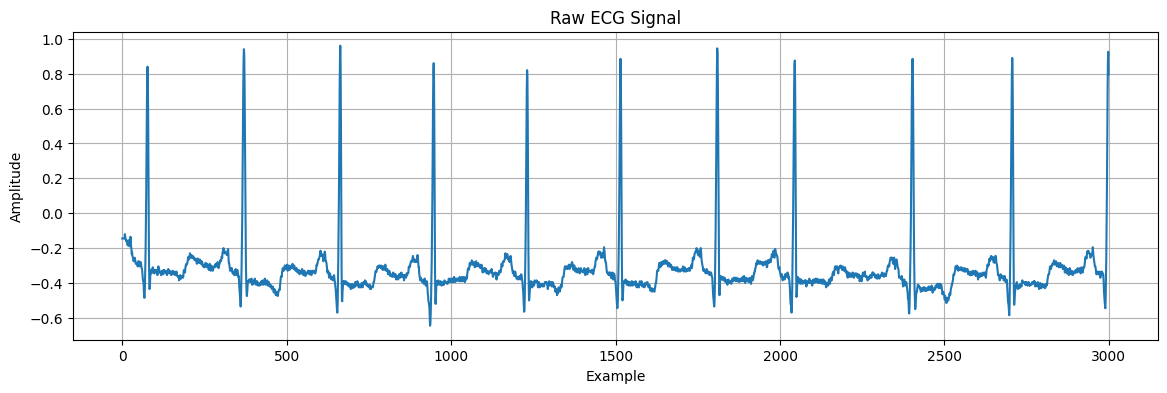

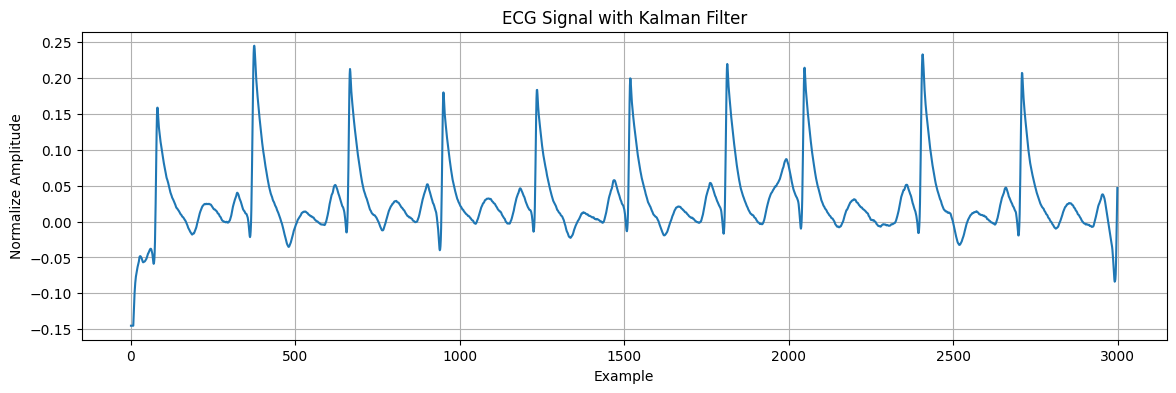

In [ ]:
example_record = '100'
record_path = os.path.join(db_dir, example_record)
record = wfdb.rdrecord(record_path)

raw_sig = record.p_signal[:3000, 0]

baseline = medfilt(raw_sig, kernel_size=201)
pre_sig = raw_sig - baseline
kalman_sig = kalman_filter_1d(pre_sig, process_variance=1e-5, measurement_variance=1e-2)

plt.figure(figsize=(14,4))
plt.plot(raw_sig)
plt.title("Raw ECG Signal")
plt.xlabel("Example")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

plt.figure(figsize=(14,4))
plt.plot(kalman_sig)
plt.title("ECG Signal with Kalman Filter")
plt.xlabel("Example")
plt.ylabel("Normalize Amplitude")
plt.grid(True)
plt.show()

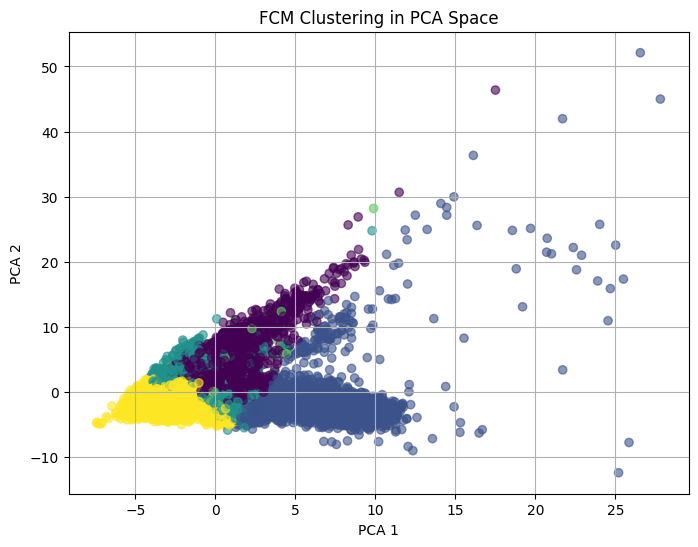

In [ ]:
from sklearn.decomposition import PCA

pca_vis = PCA(n_components=2)
X_vis = pca_vis.fit_transform(X_train_sc)

# En baskın üyelik sınıfı
cluster_ids = np.argmax(u_train, axis=0)

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_vis[:,0], X_vis[:,1], c=cluster_ids, alpha=0.6)
plt.title("FCM Clustering in PCA Space")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(True)
plt.show()

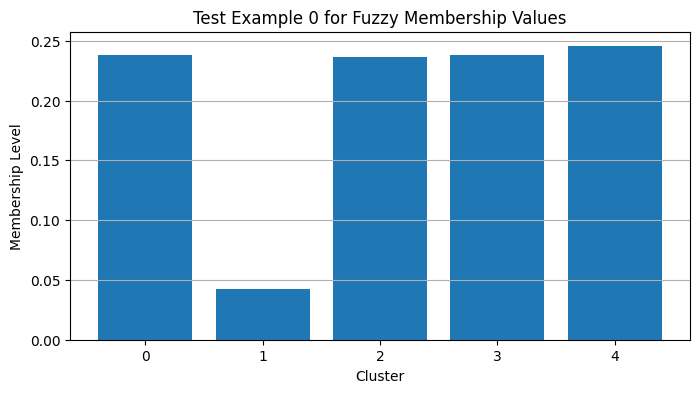

In [ ]:
sample_idx = 0
membership_values = u_test[:, sample_idx]

plt.figure(figsize=(8,4))
plt.bar(range(len(membership_values)), membership_values)
plt.title(f"Test Example {sample_idx} for Fuzzy Membership Values")
plt.xlabel("Cluster")
plt.ylabel("Membership Level")
plt.xticks(range(len(membership_values)))
plt.grid(axis='y')
plt.show()

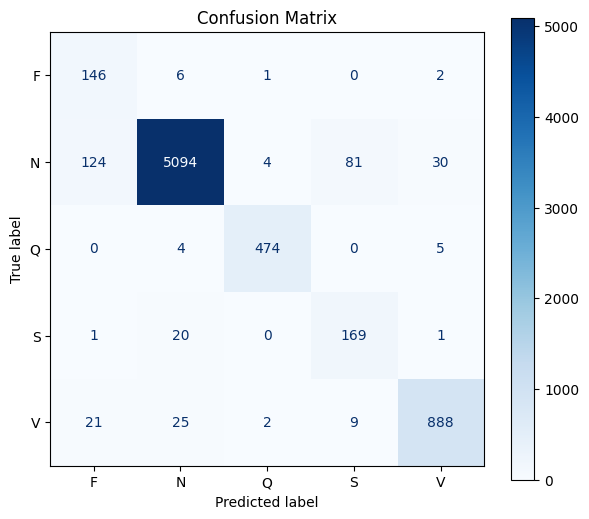

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(7,6))
disp.plot(ax=ax, cmap="Blues", values_format='d')
plt.title("Confusion Matrix")
plt.show()

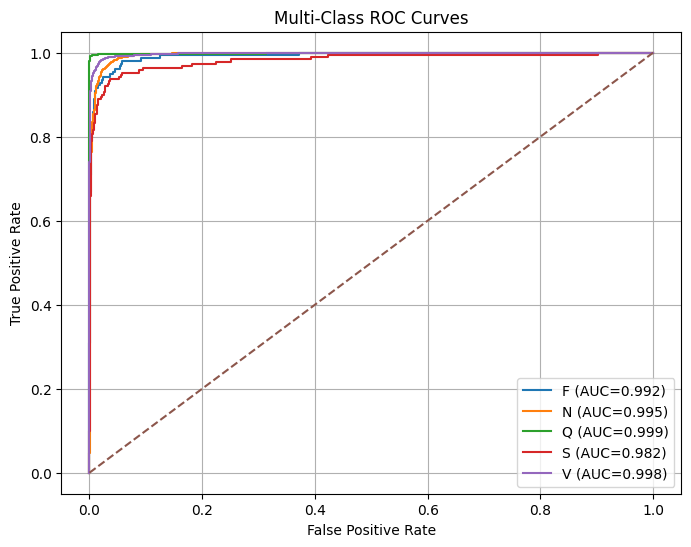

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_test_bin = label_binarize(y_test, classes=np.arange(len(class_names)))
n_classes = len(class_names)

plt.figure(figsize=(8,6))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.3f})")

plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

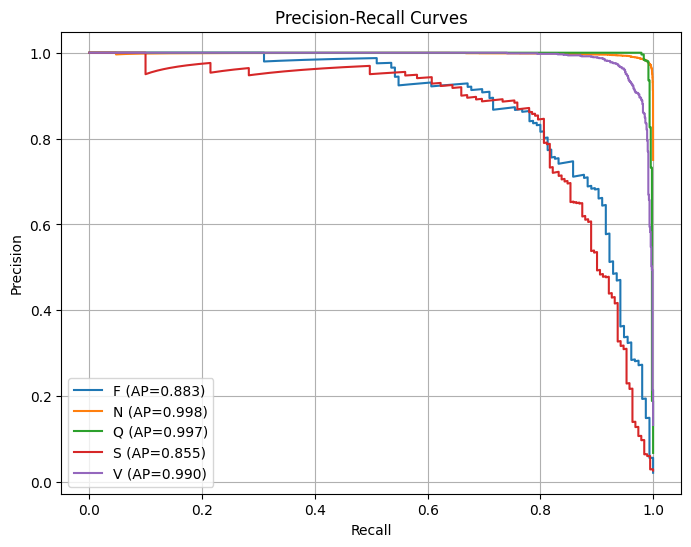

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8,6))

for i in range(n_classes):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_prob[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_prob[:, i])
    plt.plot(recall, precision, label=f"{class_names[i]} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(True)
plt.show()

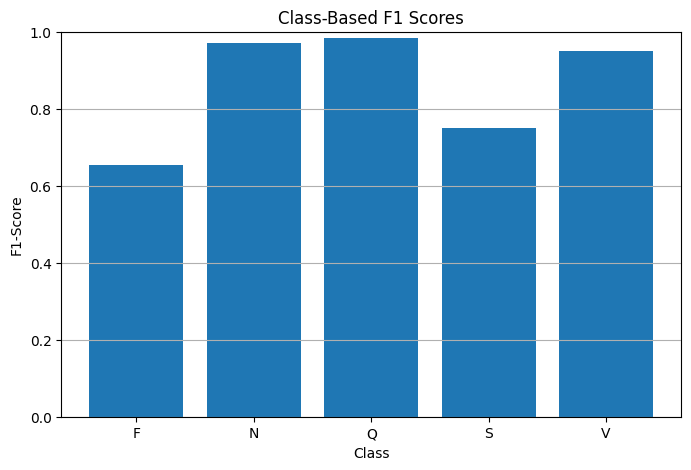

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
f1_scores = [report[c]["f1-score"] for c in class_names]

plt.figure(figsize=(8,5))
plt.bar(class_names, f1_scores)
plt.title("Class-Based F1 Scores")
plt.xlabel("Class")
plt.ylabel("F1-Score")
plt.ylim(0, 1)
plt.grid(axis='y')
plt.show()

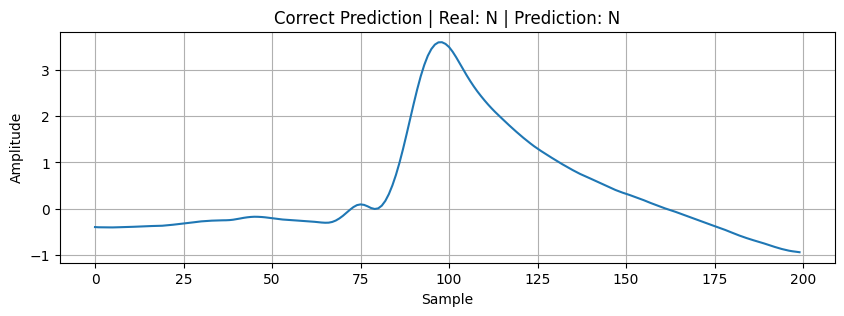

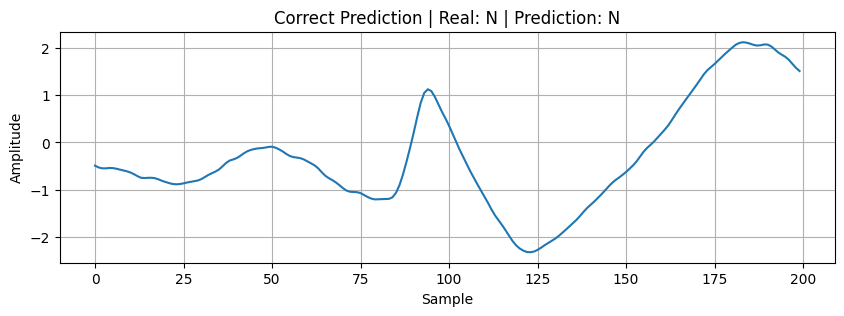

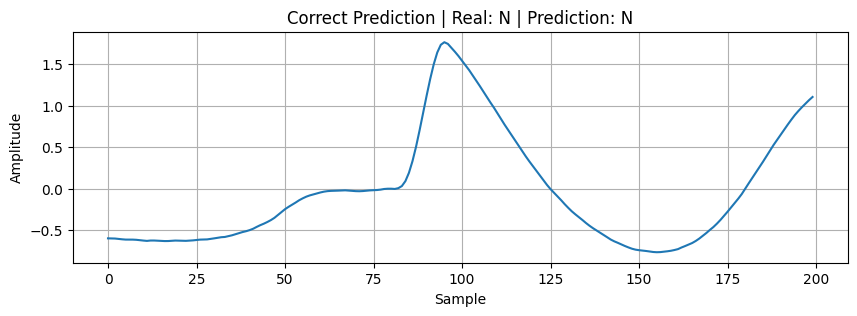

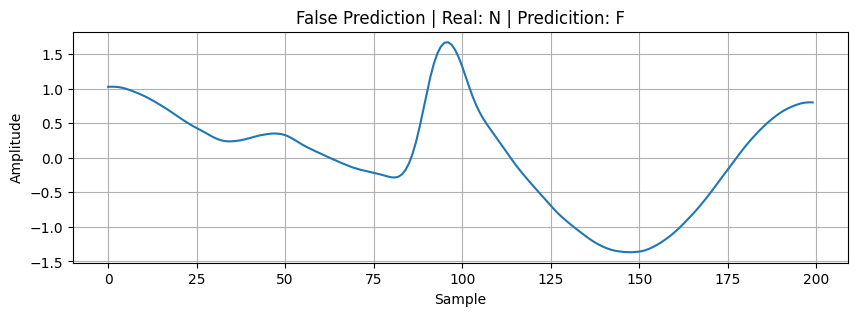

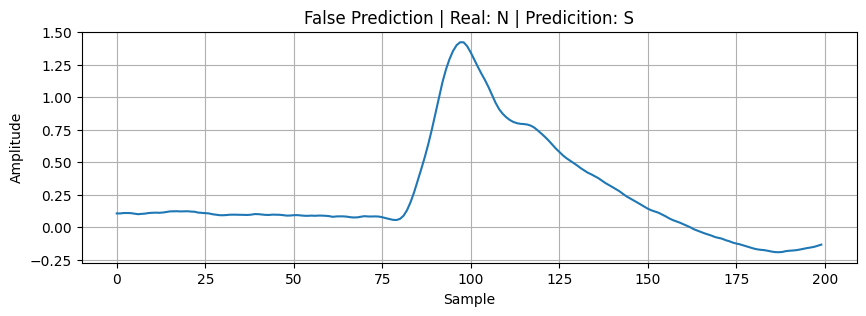

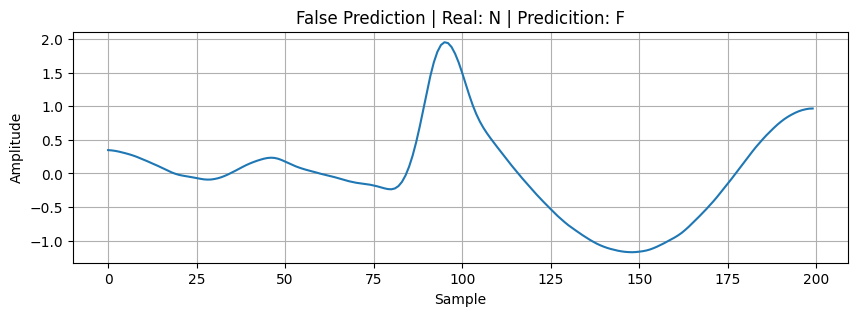

In [ ]:
correct_idx = np.where(y_test == y_pred)[0][:3]
wrong_idx = np.where(y_test != y_pred)[0][:3]

for idx in correct_idx:
    plt.figure(figsize=(10,3))
    plt.plot(beats_test[idx])
    plt.title(f"Correct Prediction | Real: {class_names[y_test[idx]]} | Prediction: {class_names[y_pred[idx]]}")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()

for idx in wrong_idx:
    plt.figure(figsize=(10,3))
    plt.plot(beats_test[idx])
    plt.title(f"False Prediction | Real: {class_names[y_test[idx]]} | Predicition: {class_names[y_pred[idx]]}")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()

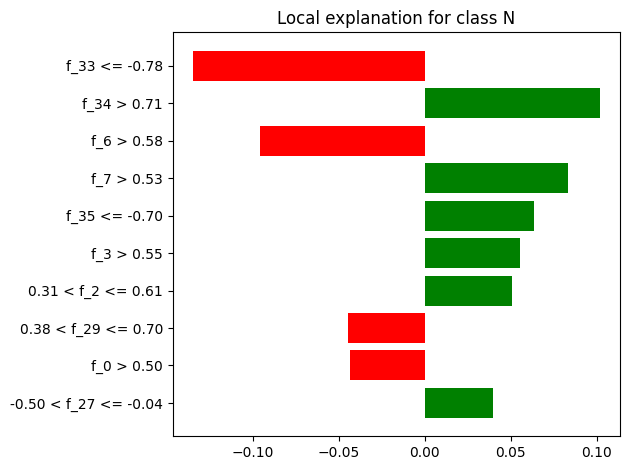

In [ ]:
fig = exp.as_pyplot_figure()
plt.tight_layout()
plt.savefig("/content/lime_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
plt.savefig("grafik_adi.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

<Figure size 700x600 with 0 Axes>

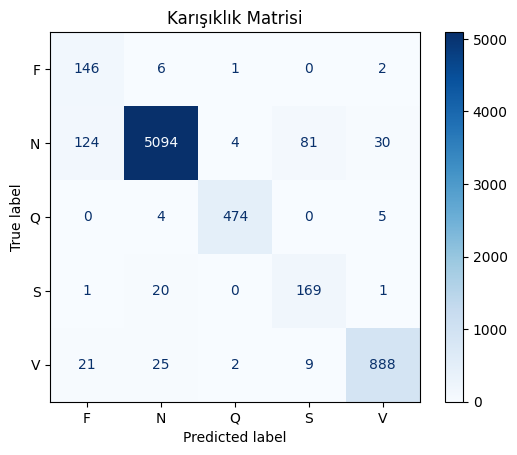

In [ ]:
plt.figure(figsize=(7,6))
disp.plot(cmap="Blues", values_format='d')
plt.title("Karışıklık Matrisi")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()